# 멀티 MCP 서버

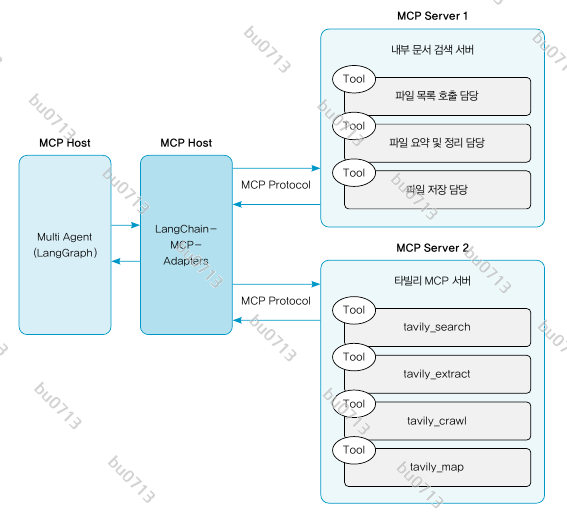


# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 18ms


In [13]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# 파일 MCP 서버 구성

In [ ]:
from mcp.server.fastmcp import FastMCP  # FastMCP: MCP 서버를 빠르게 구성하는 클래스 임포트
import os  # 파일 시스템 경로 및 디렉토리 접근용 표준 라이브러리
import stat  # 파일 모드(권한) 문자열 변환용 표준 라이브러리
import time  # 타임스탬프를 사람이 읽는 문자열로 변환하는 표준 라이브러리
from typing import List  # 반환 타입 힌트 List 임포트


mcp = FastMCP(  # [ 1 ] FastMCP 서버 인스턴스 생성
    "FileSearch",  # 서버 이름 지정
    instructions="로컬 파일 검색을 도와주는 어시스턴트입니다."  # 서버 동작 안내 문구 설정
)


# 파일 목록 호출
@mcp.tool()  # [ 2 ] 이 함수를 MCP 도구로 등록
async def file_listup(directory: str) -> List[str]:  # directory 경로를 받아 문자열 리스트 반환
    """지정된 디렉토리 경로의 파일 이름 목록을 반환합니다."""  # 도구 설명(스키마에 노출)
    try:
        return os.listdir(directory)  # 해당 디렉토리 내 항목 이름 리스트 반환
    except Exception as e:  # 접근 실패 등 예외 발생 시
        return [f"오류: {str(e)}"]  # 오류 메시지를 담은 리스트 반환


# 파일 검색 요약 및 정리 담당
@mcp.tool()  # [ 3 ] 이 함수를 MCP 도구로 등록
async def file_info(path: str) -> dict:  # path를 받아 상세 정보 딕셔너리 반환
    """
    지정된 경로의 파일 또는 디렉토리에 대한 상세 정보를 반환합니다.
    """  # 도구 설명(스키마에 노출)
    if not os.path.exists(path):  # 경로가 존재하지 않으면
        return {"error": f"경로 '{path}' 가 존재하지 않습니다."}  # 오류 딕셔너리 반환

    try:
        stat_info = os.stat(path)  # 파일 상태 정보(크기, 시간, 모드 등) 조회

        permissions = stat.filemode(stat_info.st_mode)  # 모드 값을 권한 문자열로 변환

        with open(path, "r", encoding="utf-8") as f:  # 파일을 UTF-8 텍스트 모드로 열기
            content = f.read()  # 파일 전체 내용을 문자열로 읽기

        return {
            "path": os.path.abspath(path),  # 절대 경로
            "content": content,  # 읽어들인 파일 내용
            "type": "file",  # 타입을 "file" 문자열로 지정
            "size": stat_info.st_size,  # bytes  # 파일 크기(바이트)
            "created_time": time.ctime(stat_info.st_birthtime),  # 생성 시각 문자열
            "modified_time": time.ctime(stat_info.st_mtime),  # 수정 시각 문자열
            "access_time": time.ctime(stat_info.st_atime),  # 접근 시각 문자열
            "permissions": permissions,  # 권한 문자열
        }
    except Exception as e:  # 파일 열기/조회 중 예외 발생 시
        return {"error": str(e)}  # 오류 딕셔너리 반환


# 파일 쓰기 저장 담당
@mcp.tool()  # [ 4 ] 이 함수를 MCP 도구로 등록
async def save_file(content: str, output_path="file_info.md") -> str:  # content를 output_path에 저장, 경로 반환
    """제공된 내용을 지정된 output_path의 텍스트 파일에 작성합니다."""  # 도구 설명(스키마에 노출)
    with open(output_path, "w", encoding="utf-8") as f:  # 파일을 UTF-8 쓰기 모드로 열기
        f.write(content)  # content를 파일에 기록

    return output_path  # 저장한 파일 경로 반환


if __name__ == "__main__":  # [ 5 ] 스크립트가 직접 실행될 때만 아래 코드 실행
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

서버 커기

 uv run fileserver.py 

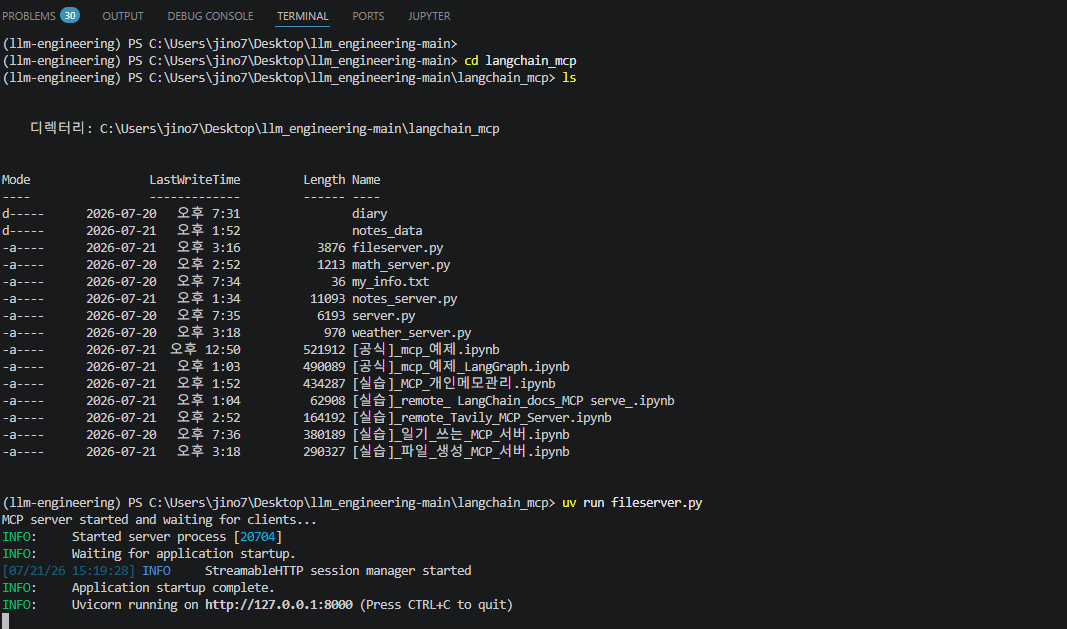

# MCP 클라이언트 에이전트 방식

라이브러리 임포트 및 2개 MCP 클라이언트 구성

In [14]:
# ============================================
# [셀 1] 라이브러리 임포트 및 2개 MCP 클라이언트 구성
# ============================================
import os  # 환경 변수 접근용 표준 라이브러리
import gradio as gr
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_mcp_adapters.prompts import load_mcp_prompt
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

# .env 파일에 정의된 환경 변수를 현재 프로세스의 환경 변수로 로드
load_dotenv()

# 환경 변수에서 Tavily API 키 값을 읽어옴
TAVILY_API_KEY = os.environ.get("TAVILY_API_KEY")

# 에이전트의 시스템 프롬프트(역할·행동 지침) 문자열
# create_agent에 str로 전달되면 내부에서 SystemMessage로 변환되어
# 매 모델 호출 시 메시지 목록 맨 앞에 추가됨
SYSTEM_PROMPT = (
    "당신은 로컬 파일 관리와 웹 검색을 함께 수행하는 AI 비서입니다. "
    "FileSearch 도구로 로컬 파일을 조회, 검색, 생성, 저장할 수 있고, "
    "Tavily 검색 도구로 웹에서 최신 정보를 찾을 수 있습니다. "
    "사용자 요청이 로컬 파일에 관한 것이면 FileSearch 도구를 사용하고, "
    "최신 정보나 외부 지식이 필요하면 Tavily 검색 도구를 사용하세요. "
    "웹 검색 결과를 파일로 저장해 달라는 요청이 있으면, "
    "검색 결과를 정리한 뒤 save_file 도구로 저장하세요. "
    "사용자로부터 파일의 내용을 중심으로 입력받고, "
    "제목이나 태그가 명시되지 않았다면 자동으로 생성하여 저장하세요."
)

# 사용할 LLM 모델 정의
model = ChatOpenAI(model="gpt-5-mini")

# 2개의 MCP 서버에 각각 streamable_http 전송 방식으로 연결하는 클라이언트를 생성
# - FileSearch: 로컬 server.py가 포트 8000에서 실행 중이어야 함
# - tavily: 원격 Tavily MCP 서버, URL 쿼리 파라미터로 API 키를 전달
client = MultiServerMCPClient(
    {
        "FileSearch": {
            "url": "http://localhost:8000/mcp",  # 로컬 파일 서버 엔드포인트
            "transport": "streamable_http",  # HTTP 스트리밍 전송 방식
        },
        "tavily": {
            "transport": "streamable_http",  # HTTP 스트리밍 전송 방식
            # URL 쿼리 파라미터로 Tavily API 키를 전달 (끝에 슬래시 포함)
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}",
        },
    }
)

# 대화 기록을 저장하는 체크포인터
# 매 요청마다 에이전트를 새로 만들더라도, 같은 thread_id로 조회하면
# 이전 대화 내용이 그대로 이어짐
checkpointer = InMemorySaver()

Gradio에서 호출할 비동기 응답 함수

In [15]:
# ============================================
# [셀 2] Gradio에서 호출할 비동기 응답 함수 (진행 과정 스트리밍)
# ============================================
async def respond(message, history):
    """
    Gradio ChatInterface가 호출하는 응답 함수.
    message: 사용자가 방금 입력한 텍스트
    history: 지금까지의 화면상 대화 기록 (list)
    """
    # 2개 MCP 서버(FileSearch, tavily)의 tool들을 한 번에 LangChain tool 형태로 변환
    tools = await client.get_tools()

    # system_prompt로 역할 지침을 전달하여 에이전트 생성
    agent = create_agent(
        model,
        tools,
        system_prompt=SYSTEM_PROMPT,
        checkpointer=checkpointer,
    )

    # 화면에 누적 출력할 진행 과정 문자열
    progress = ""

    # astream을 stream_mode="updates"로 실행하면 각 노드가 끝날 때마다
    # {노드이름: {"messages": [...]}} 형태의 업데이트가 하나씩 전달됨
    async for chunk in agent.astream(
        {"messages": [{"role": "user", "content": message}]},
        config={"configurable": {"user_id": "user_123", "thread_id": "1"}},
        stream_mode="updates",
    ):
        # 노드 이름에 관계없이 각 업데이트의 messages를 순회
        for node_output in chunk.values():
            for msg in node_output.get("messages", []):
                # AI 메시지가 도구 호출을 포함하는 경우 (tool_calls 존재)
                if getattr(msg, "tool_calls", None):
                    for tc in msg.tool_calls:
                        # 호출한 도구 이름과 인자를 진행 과정에 추가
                        progress += f"🔧 도구 호출: `{tc['name']}` 인자={tc['args']}\n\n"
                        yield progress  # 갱신된 진행 과정을 화면에 반영

                # 도구 실행 결과 메시지인 경우 (메시지 타입이 "tool")
                elif getattr(msg, "type", None) == "tool":
                    # 결과가 길 수 있으므로 앞부분 300자만 표시
                    result = str(msg.content)[:300]
                    progress += f"📄 도구 결과: {result}\n\n"
                    yield progress  # 갱신된 진행 과정을 화면에 반영

                # 도구 호출 없이 텍스트 content만 있는 AI 메시지 = 최종 응답
                elif getattr(msg, "content", None):
                    progress += f"💬 최종 응답:\n\n{msg.content}\n"
                    yield progress  # 최종 응답까지 포함해 화면에 반영

Gradio UI 실행

오늘 서울 날씨 웹에서 검색한 후 정리해서 seoul.md 파일로 저장해줘

In [16]:
# ============================================
# [셀 3] Gradio UI 실행
# ============================================
demo = gr.ChatInterface(
    fn=respond,                # 비동기 함수도 그대로 전달 가능
    type="messages",           # OpenAI 스타일 messages 형식 사용
    title="MCP 파일 + 웹 검색 비서",
    description="로컬 파일을 검색·생성하고, Tavily로 웹 최신 정보를 검색할 수 있습니다.",
    examples=[
        "현재 디렉토리의 파일 목록을 보여줘",
        "2025년 최신 AI 에이전트 트렌드를 웹에서 검색해줘",
        "LangGraph에 대해 웹에서 검색한 뒤 내용을 정리해서 langgraph.md 파일로 저장해줘",
    ],
)

# 주피터 노트북에서는 launch() 호출 시 셀 출력 영역에 UI가 인라인으로 표시됨
demo.launch()

* Running on local URL:  http://127.0.0.1:7869
* To create a public link, set `share=True` in `launch()`.


# LangGraph 방식

https://github.com/langchain-ai/langchain-mcp-adapters#using-with-langgraph-stategraph


In [ ]:
# ============================================
# [셀 1] 임포트 · 모델 · 프롬프트 · 클라이언트
# ============================================
import os  # 환경 변수 접근용 표준 라이브러리
import gradio as gr  # 웹 UI 구성용 라이브러리
from dotenv import load_dotenv  # .env 파일 로드용 함수

from langchain.chat_models import init_chat_model  # 공급자 문자열로 모델을 생성하는 함수
from langchain_mcp_adapters.client import MultiServerMCPClient  # 여러 MCP 서버 연결 클라이언트
from langchain_core.messages import SystemMessage  # 시스템 프롬프트를 메시지로 주입하기 위한 타입
from langgraph.graph import StateGraph, MessagesState, START  # 그래프 구성 요소
from langgraph.prebuilt import ToolNode, tools_condition  # 도구 실행 노드와 분기 조건 함수
from langgraph.checkpoint.memory import InMemorySaver  # 대화 기록 메모리 체크포인터

# .env 파일의 환경 변수를 현재 프로세스로 로드
load_dotenv()
# 환경 변수에서 Tavily API 키 값을 읽어옴
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")

# 공급자 접두어 형식으로 모델 생성 (참조 코드의 init_chat_model 방식 사용)
model = init_chat_model("openai:gpt-5-mini")

# 에이전트의 역할·행동 지침 문자열
# call_model 노드에서 SystemMessage로 감싸 매 모델 호출 맨 앞에 주입됨
SYSTEM_PROMPT = (
    "당신은 로컬 파일 관리와 웹 검색을 함께 수행하는 AI 비서입니다. "
    "FileSearch 도구로 로컬 파일을 조회, 검색, 생성, 저장할 수 있고, "
    "Tavily 검색 도구로 웹에서 최신 정보를 찾을 수 있습니다. "
    "로컬 파일에 관한 요청이면 파일 도구를, 최신 정보나 외부 지식이 필요하면 "
    "웹 검색 도구를 사용하세요. 웹 검색 결과를 파일로 저장해 달라는 요청이 있으면 "
    "검색 결과를 정리한 뒤 save_file 도구로 저장하세요."
)

# 2개의 MCP 서버에 각각 streamable_http 전송 방식으로 연결하는 클라이언트 생성
# - file: 로컬 server.py가 8000 포트에서 streamable-http로 실행 중이어야 함
# - tavily: 원격 Tavily MCP 서버, URL 쿼리 파라미터로 API 키 전달
client = MultiServerMCPClient(
    {
        "tavily": {
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}",  # 원격 엔드포인트
            "transport": "streamable_http",  # HTTP 스트리밍 전송 방식
        },
        "file": {
            "url": "http://localhost:8000/mcp",  # 로컬 파일 서버 엔드포인트
            "transport": "streamable_http",  # HTTP 스트리밍 전송 방식
        },
    }
)

In [7]:
# ============================================
# [셀 2] 도구 로드 · 노드 정의 · 그래프 컴파일
# (Jupyter는 셀에서 top-level await 사용 가능)
# ============================================

# 2개 서버의 도구를 하나의 리스트로 합쳐서 로드
tools = await client.get_tools()


# 모델 호출 노드: 시스템 프롬프트를 맨 앞에 붙이고 도구를 바인딩해 모델 호출
def call_model(state: MessagesState):
    # 매 호출마다 시스템 프롬프트를 메시지 목록 맨 앞에 주입
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    # 도구를 바인딩한 모델을 호출 (모델이 필요 시 tool_calls를 생성)
    response = model.bind_tools(tools).invoke(messages)
    # 응답 메시지를 상태에 반영 (MessagesState의 add_messages 리듀서가 누적)
    return {"messages": response}


# 그래프 구성: call_model 과 도구 실행 노드(ToolNode) 등록
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)  # 모델 호출 노드 등록
builder.add_node("tools", ToolNode(tools))  # 도구 실행 노드 등록 (이름 "tools" 고정)
builder.add_edge(START, "call_model")  # 시작 지점을 모델 호출로 연결

# call_model 이후 분기:
# tools_condition은 마지막 메시지에 tool_calls가 있으면 "tools"로,
# 없으면 END로 보냄 → 도구 호출이 없으면 자동 종료 (구조적 루프 방지)
builder.add_conditional_edges("call_model", tools_condition)

# 도구 실행이 끝나면 다시 모델 호출로 돌아가 결과를 반영
builder.add_edge("tools", "call_model")

# 대화 기록 유지를 위한 메모리 체크포인터와 함께 그래프 컴파일
memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

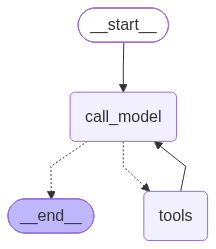

In [8]:
graph

In [9]:
# ============================================
# [셀 3] Gradio 응답 함수 (진행 과정 누적 출력)
# ============================================
async def respond(message, history):
    """
    Gradio ChatInterface가 호출하는 응답 함수.
    message: 사용자가 방금 입력한 텍스트
    history: 지금까지의 화면상 대화 기록 (list)
    """
    progress = ""  # 화면에 누적 출력할 진행 과정 문자열
    # thread_id로 대화 이어가기, recursion_limit은 만일의 과도한 반복에 대한 보조 안전장치
    config = {
        "recursion_limit": 25,
        "configurable": {"thread_id": "1"},
    }

    # updates 모드로 각 노드가 끝날 때마다 갱신 내용을 받음
    async for chunk in graph.astream(
        {"messages": [{"role": "user", "content": message}]},
        stream_mode="updates",
        config=config,
    ):
        # chunk는 {노드이름: {"messages": ...}} 형태이므로 노드별로 순회
        for node_name, node_chunk in chunk.items():
            msg = node_chunk["messages"]  # 해당 노드가 반영한 메시지
            # 도구 노드는 메시지가 리스트로 올 수 있어 마지막 항목만 취함
            if isinstance(msg, list):
                msg = msg[-1]

            # 모델이 도구 호출을 결정한 경우
            if getattr(msg, "tool_calls", None):
                for tc in msg.tool_calls:
                    progress += f"🔧 도구 호출: `{tc['name']}` 인자={tc['args']}\n\n"
            # 도구 실행 결과 메시지인 경우
            elif getattr(msg, "type", None) == "tool":
                result = str(msg.content)[:300]  # 결과가 길 수 있어 앞부분만 표시
                progress += f"📄 도구 결과: {result}\n\n"
            # 도구 호출 없이 텍스트만 있는 최종 응답인 경우
            elif getattr(msg, "content", None):
                progress += f"💬 최종 응답:\n\n{msg.content}\n"

            yield progress  # 갱신될 때마다 화면에 반영

In [10]:
# ============================================
# [셀 4] Gradio UI 실행
# ============================================
demo = gr.ChatInterface(
    fn=respond,                # 비동기 제너레이터 함수 전달 (진행 과정 스트리밍)
    type="messages",           # OpenAI 스타일 messages 형식 사용
    title="MCP 파일 + 웹 검색 비서",
    description="파일 도구와 Tavily 웹 검색 도구를 하나의 그래프에서 함께 사용합니다.",
    examples=[
        "현재 디렉토리의 파일 목록을 보여줘",
        "2025년 최신 AI 에이전트 트렌드를 웹에서 검색해줘",
        "현재 서울을 날씨를 웹에서 검색한 후 정리해서 seoul2.md 파일로 저장해줘",
    ],
)

# 주피터 노트북에서는 launch() 호출 시 셀 출력 영역에 UI가 인라인으로 표시됨
demo.launch()

* Running on local URL:  http://127.0.0.1:7868
* To create a public link, set `share=True` in `launch()`.
